# Лабораторная работа №9: Fine-tuning VLM с помощью LLaMA-Factory

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Преобразовать мультимодальные данные в instruction format.
- Сформировать QLoRA YAML и запустить SFT.
- Сравнить base и adapter, включая OOD slice.


## Теоретическая часть

SFT минимизирует autoregressive loss только на целевом ответе. QLoRA хранит base weights в 4-bit NF4 и обучает low-rank update $\Delta W=BA$, что уменьшает память. LLaMA-Factory фиксирует pipeline в YAML-конфигурации.


**QLoRA** — метод экономного дообучения больших моделей. Основные веса модели хранятся в 4-битном формате, а обучение выполняется с помощью небольших дополнительных матриц LoRA. Это позволяет уменьшить потребление видеопамяти и не обучать все параметры модели заново.

**LLaMA-Factory** — инструмент, который помогает настраивать и запускать обучение моделей с помощью конфигурационных файлов.

### Математическая постановка

$$
W' = W_q + \frac{\alpha}{r}BA,\quad B\in\mathbb{R}^{d\times r},\ A\in\mathbb{R}^{r\times k}.
$$

Обучаются только $A,B$; сравнение проводится с той же base model и evaluation set.


### Материалы

- [LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)
- [QLoRA](https://arxiv.org/abs/2305.14314)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Вход — лицензированный предметный корпус `data/lab9/manifest.jsonl` с независимыми train/validation/ID/OOD. Получение и экспертная проверка данных обязательны; файл не заменяется выдуманным изображением. В Colab установите совместимый LLaMA-Factory из зафиксированного commit и запишите commit в отчёт. CLI запускается непосредственно из ноутбука. Полный режим означает фактическое обучение и сравнение; `FAST_DEV_RUN` обучает два шага только для проверки стека. Оценку общей способности выполните на отдельном общем VQA-наборе с заранее выбранной метрикой.

In [10]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 79
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n', encoding='utf-8')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


In [1]:
%pip install llamafactory

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.7/69.7 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.7/87.7 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 482.7/482.7 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 375.8/375.8 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 MB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 494.8/494.8 kB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 MB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.6/325.6 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.0/557.0 kB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 462.4/462.4 kB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
%pip install -U bitsandbytes>=0.46.1

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Манифест и независимые разбиения

*Вес: 1 балл.*

**Постановка.** Загрузите ScienceQA функцией prepare_scienceqa. Сформируйте 512 train и по 64 validation, ID, OOD и general примера с изображениями. ID: natural science, классы 1–6; OOD: тот же предмет, классы 7–12; general: другие предметы. Используйте официальные split и исключите повторные изображения по хешу.

**Результат.** manifest.jsonl и ATTRIBUTION.md.

**Критерий принятия.** Количество записей соответствует протоколу; ни одно изображение не используется в двух разбиениях; версия и лицензия источника указаны.


In [11]:
# Библиотеки

from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image

In [12]:
DATA_DIR = Path("data/lab9")
DATA_DIR.mkdir(parents=True, exist_ok=True)

manifest_name = "manifest-smoke.jsonl" if FAST_DEV_RUN else "manifest.jsonl"
manifest_path = DATA_DIR / manifest_name

def read_manifest(path):
    with path.open("r", encoding="utf-8-sig") as f:
        return [json.loads(line) for line in f if line.strip()]

# Если существующий манифест повреждён, удаляем его.
if manifest_path.exists():
    try:
        records = read_manifest(manifest_path)
    except (UnicodeDecodeError, json.JSONDecodeError):
        manifest_path.unlink()
        records = None
else:
    records = None

# Если файла нет или он повреждён, создаём заново.
if records is None:
    manifest_path = prepare_scienceqa(DATA_DIR, smoke=FAST_DEV_RUN)
    records = read_manifest(manifest_path)

limits = {
    "train": 8 if FAST_DEV_RUN else 512,
    "validation": 4 if FAST_DEV_RUN else 64,
    "id_test": 4 if FAST_DEV_RUN else 64,
    "ood_test": 4 if FAST_DEV_RUN else 64,
    "general_test": 4 if FAST_DEV_RUN else 64,
}

counts = {
    split: sum(r["split"] == split for r in records)
    for split in limits
}
assert counts == limits, f"Неверные размеры разбиений: {counts}"

from PIL import Image

seen_hashes = set()

for r in records:
    path = Path(r["image"])
    assert path.is_file(), f"Изображение не найдено: {path}"
    assert r["question"].strip()
    assert r["answer"] == chr(65 + r["answer_index"])
    assert 0 <= r["answer_index"] < len(r["choices"])
    assert r["image_sha256"] not in seen_hashes, "Найден дубликат"
    seen_hashes.add(r["image_sha256"])

    with Image.open(path) as img:
        img.verify()

print("Манифест проверен:", manifest_path)


Манифест проверен: data/lab9/manifest.jsonl


### Визуальный аудит корпуса

*Вес: 1 балл.*

**Постановка.** Декодируйте изображения и постройте сетку примеров с вопросами и правильными буквами. Подсчитайте распределение ответов по каждому split: возможный перевес одной буквы следует учитывать при интерпретации accuracy.

**Результат.** data_profile.json и data_preview.png.

**Критерий принятия.** Показаны реальные изображения; правильная буква соответствует индексированному варианту; представлены частоты всех букв отдельно по split.


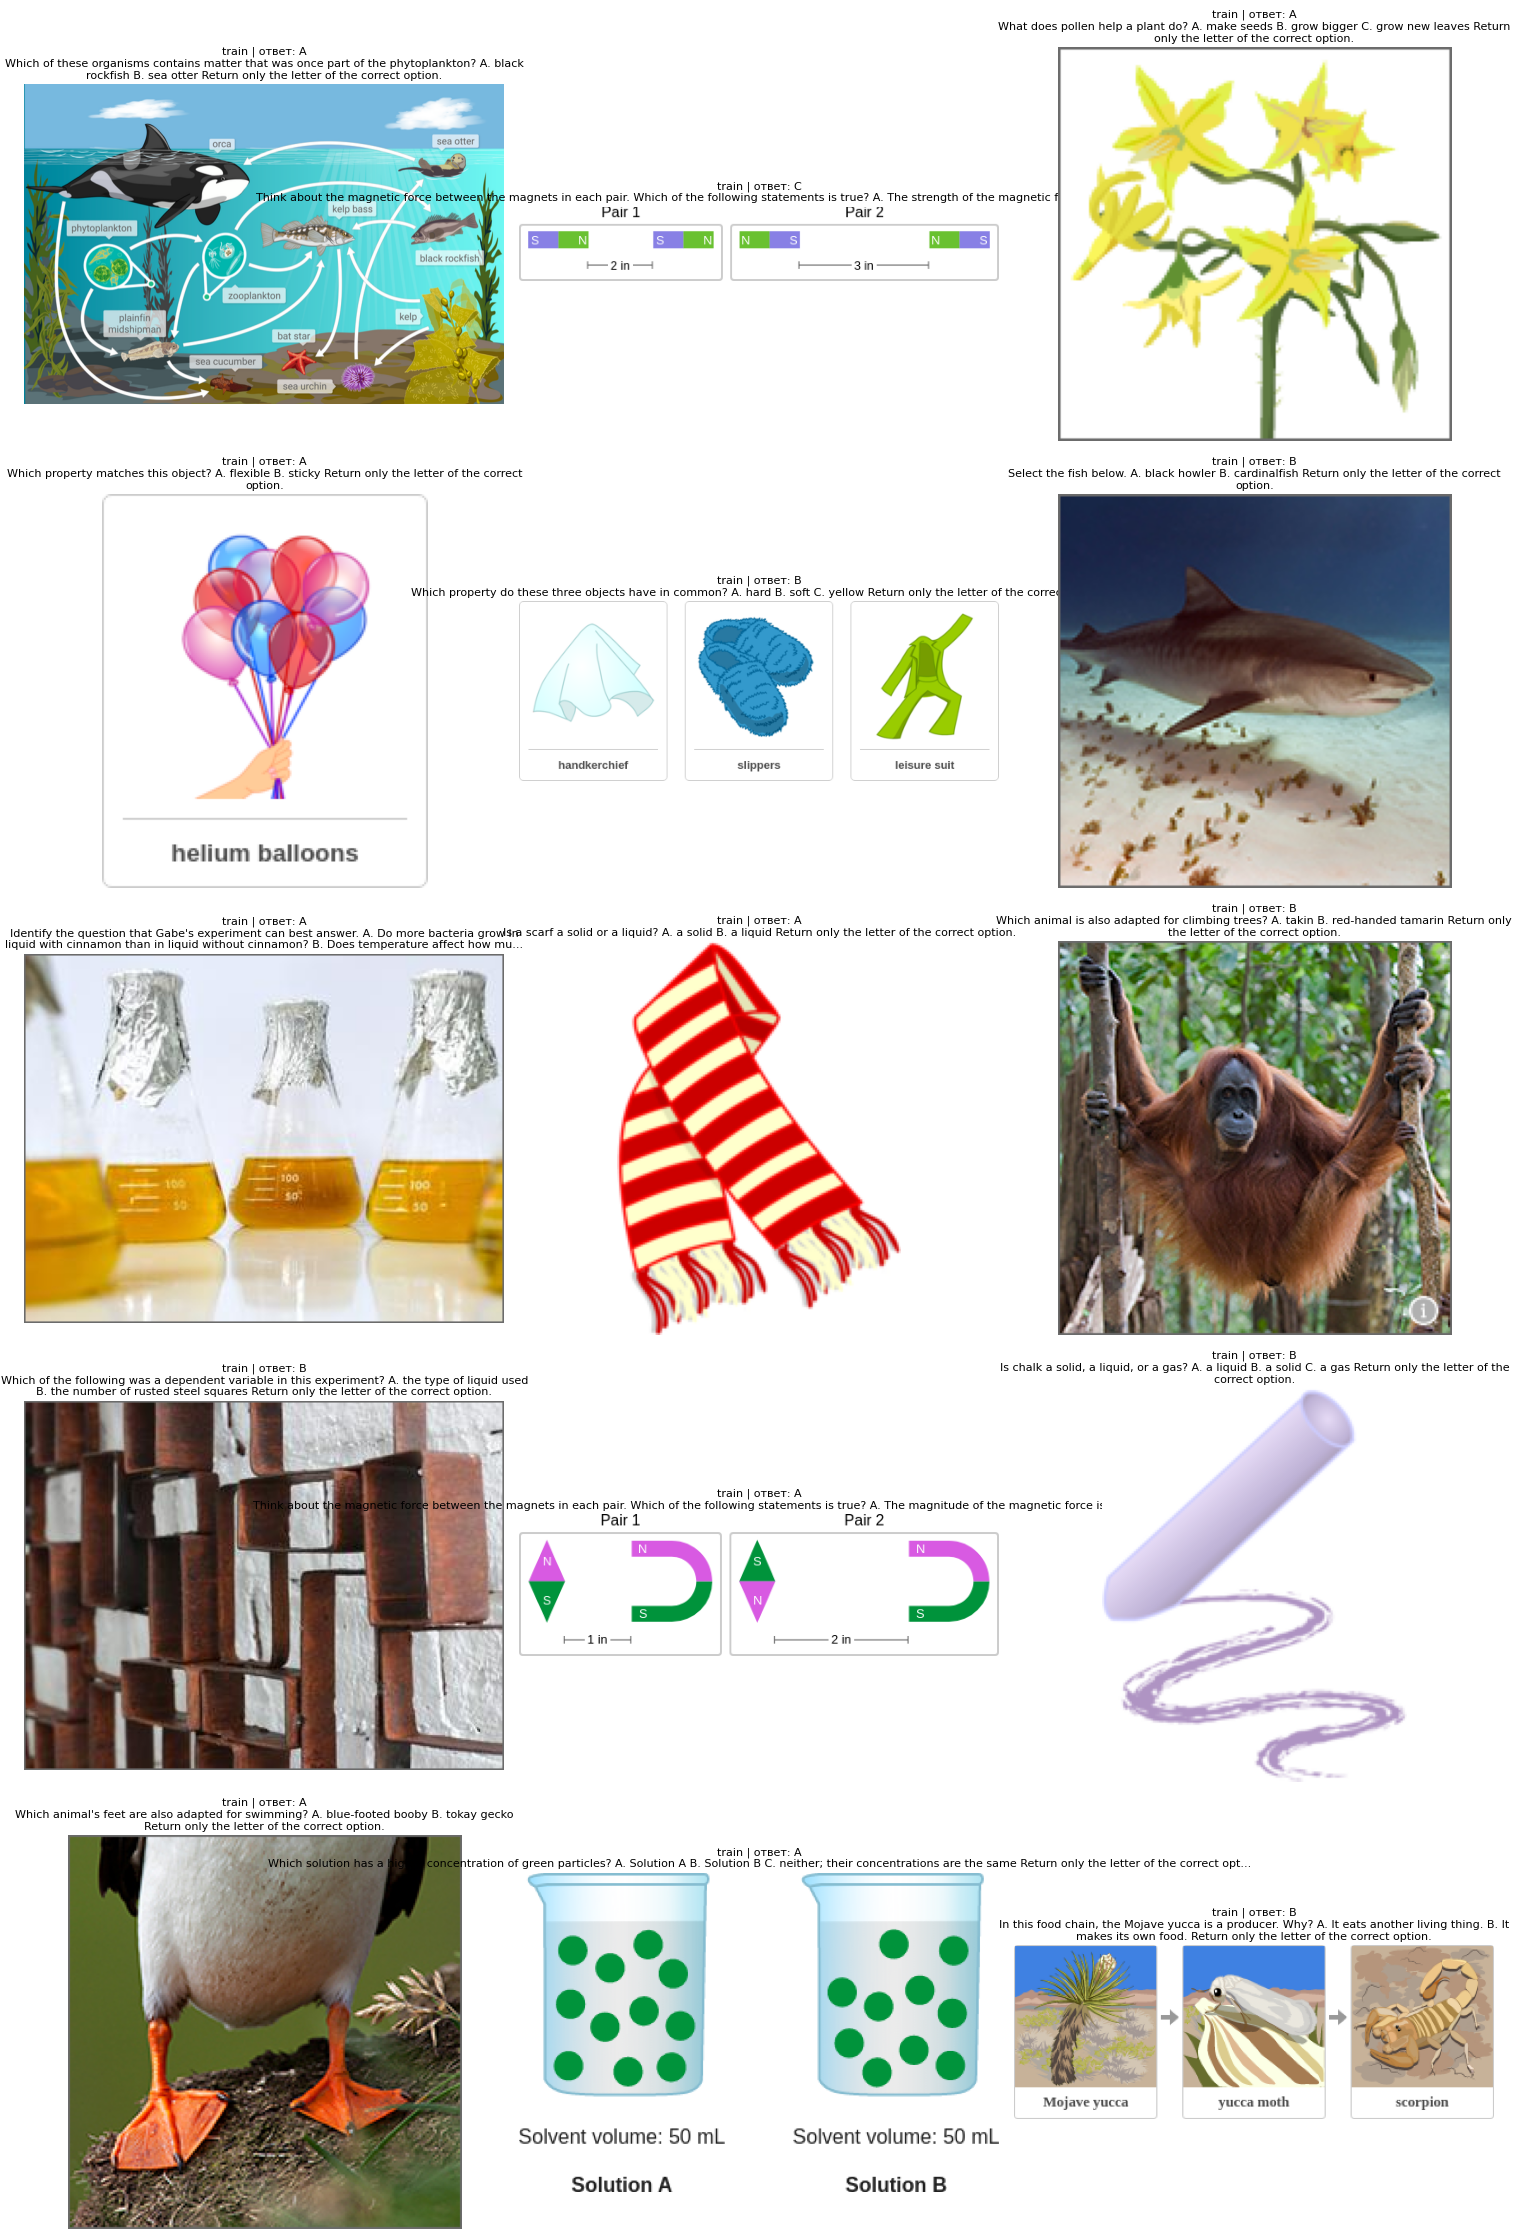

Профиль: artifacts/data_profile.json
Визуальный аудит: artifacts/data_preview.png


In [13]:
PROFILE_PATH = ARTIFACTS / "data_profile.json"
PREVIEW_PATH = ARTIFACTS / "data_preview.png"

splits = ["train", "validation", "id_test", "ood_test", "general_test"]

# Распределение ответов по каждому split, включая нулевые частоты
max_choices = max(len(r["choices"]) for r in records)
letters = [chr(65 + i) for i in range(max_choices)]

profile = {
    "manifest": str(manifest_path),
    "fast_dev_run": FAST_DEV_RUN,
    "num_examples": len(records),
    "splits": {},
}

for split in splits:
    subset = [r for r in records if r["split"] == split]
    answer_counts = Counter(r["answer"] for r in subset)

    profile["splits"][split] = {
        "count": len(subset),
        "answer_distribution": {
            letter: answer_counts.get(letter, 0)
            for letter in letters
        },
        "accuracy_baseline_random_uniform": (
            sum(1 / len(r["choices"]) for r in subset) / len(subset)
            if subset else None
        ),
    }

PROFILE_PATH.write_text(
    json.dumps(profile, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# До 15 примеров, чтобы визуальный аудит был быстрым
n_preview = min(15, len(records))
preview_records = records[:n_preview]

cols = 3
rows = (n_preview + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 4.5 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, r in zip(axes, preview_records):
    with Image.open(r["image"]) as img:
        ax.imshow(img.convert("RGB"))

    question = " ".join(r["question"].split())
    if len(question) > 180:
        question = question[:177] + "..."

    ax.set_title(
        f'{r["split"]} | ответ: {r["answer"]}\n{question}',
        fontsize=8,
        wrap=True,
    )
    ax.axis("off")

for ax in axes[n_preview:]:
    ax.axis("off")

fig.tight_layout()
fig.savefig(PREVIEW_PATH, dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Профиль: {PROFILE_PATH}")
print(f"Визуальный аудит: {PREVIEW_PATH}")


### Экспорт мультимодального датасета

*Вес: 1 балл.*

**Постановка.** Преобразуйте записи в ShareGPT: сообщение пользователя содержит один маркер <image> и вопрос с вариантами, ответ ассистента — правильную букву. Зарегистрируйте train и validation в dataset_info.json.

**Результат.** train.json, validation.json и dataset_info.json.

**Критерий принятия.** Пути изображений разрешаются; роли и столбцы соответствуют формату LLaMA-Factory; test не попал в обучение.


In [14]:
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Используем уже загруженный records и сохраняем только train/validation.
train_records = [r for r in records if r["split"] == "train"]
val_records = [r for r in records if r["split"] == "validation"]

def to_sharegpt(record):
    image_path = Path(record["image"]).resolve()
    if not image_path.is_file():
        raise FileNotFoundError(f"Изображение не найдено: {image_path}")

    return {
        "messages": [
            {
                "role": "user",
                "content": f"<image>\n{record['question']}",
            },
            {
                "role": "assistant",
                "content": record["answer"],
            },
        ],
        "images": [str(image_path)],
    }

train_data = [to_sharegpt(r) for r in train_records]
validation_data = [to_sharegpt(r) for r in val_records]

train_path = ARTIFACTS / "train.json"
validation_path = ARTIFACTS / "validation.json"
dataset_info_path = ARTIFACTS / "dataset_info.json"

train_path.write_text(
    json.dumps(train_data, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
validation_path.write_text(
    json.dumps(validation_data, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Регистрация наборов для LLaMA-Factory.
# Пути к JSON указываются относительно ARTIFACTS.
dataset_info = {
    "lab9_train": {
        "file_name": "train.json",
        "formatting": "sharegpt",
        "columns": {
            "messages": "messages",
            "images": "images",
        },
        "tags": {
            "role_tag": "role",
            "content_tag": "content",
            "user_tag": "user",
            "assistant_tag": "assistant",
        },
    },
    "lab9_validation": {
        "file_name": "validation.json",
        "formatting": "sharegpt",
        "columns": {
            "messages": "messages",
            "images": "images",
        },
        "tags": {
            "role_tag": "role",
            "content_tag": "content",
            "user_tag": "user",
            "assistant_tag": "assistant",
        },
    },
}

dataset_info_path.write_text(
    json.dumps(dataset_info, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Минимальные проверки формата и отсутствия тестовых данных.
assert len(train_data) == len(train_records)
assert len(validation_data) == len(val_records)

for dataset in (train_data, validation_data):
    for item in dataset:
        assert len(item["messages"]) == 2
        user_msg, assistant_msg = item["messages"]
        assert user_msg["role"] == "user"
        assert user_msg["content"].count("<image>") == 1
        assert assistant_msg["role"] == "assistant"
        assert assistant_msg["content"] in "ABCDEFGH"
        assert len(item["images"]) == 1
        assert Path(item["images"][0]).is_file()

assert not any(
    r["split"] in {"id_test", "ood_test", "general_test"}
    for r in train_records + val_records
)

print("Экспорт завершён:", ARTIFACTS.resolve())

Экспорт завершён: /content/artifacts


### Конфигурация QLoRA SFT

*Вес: 1 балл.*

**Постановка.** Настройте Qwen2.5-VL-3B-Instruct, NF4, LoRA rank 8 и alpha 16, batch 1 с accumulation 16, learning rate 1e-4 и 100 шагов. Включите validation каждые 20 шагов.

**Результат.** sft.yaml.

**Критерий принятия.** YAML содержит реальные идентификаторы данных и модели, включает do_train/do_eval и сохраняет checkpoint; полный режим не ограничен двумя smoke-шагами.


In [15]:
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Все пути к датасетам должны соответствовать экспорту из предыдущего задания.
assert (ARTIFACTS / "train.json").is_file()
assert (ARTIFACTS / "validation.json").is_file()
assert (ARTIFACTS / "dataset_info.json").is_file()

# Smoke-режим проверяет конфигурацию пятью шагами.
# Полный режим задаёт все 100 шагов лабораторной работы.
max_steps = 5 if FAST_DEV_RUN else 100

config = f"""# QLoRA SFT: Qwen2.5-VL-3B-Instruct
# Для реального обучения требуется совместимая среда с CUDA GPU.
model_name_or_path: Qwen/Qwen2.5-VL-3B-Instruct
trust_remote_code: true

# Dataset files and dataset_info.json are in ARTIFACTS.
dataset_dir: {ARTIFACTS.resolve().as_posix()}
dataset: lab9_train
eval_dataset: lab9_validation
template: qwen2_vl

# Supervised fine-tuning
stage: sft
do_train: true
do_eval: true
finetuning_type: lora

# LoRA
lora_rank: 8
lora_alpha: 16
lora_target: all

# QLoRA: 4-bit NF4
quantization_bit: 4
quantization_method: bitsandbytes
quantization_type: nf4
double_quantization: true

# Memory-conscious settings
cutoff_len: 1024
per_device_train_batch_size: 1
per_device_eval_batch_size: 1
gradient_accumulation_steps: 16
gradient_checkpointing: true
preprocessing_num_workers: 1
dataloader_num_workers: 0

# Optimization
learning_rate: 1.0e-4
max_steps: {max_steps}
lr_scheduler_type: cosine
warmup_ratio: 0.05
max_grad_norm: 1.0

# Validation and checkpointing
eval_strategy: steps
eval_steps: 20
save_strategy: steps
save_steps: 20
logging_steps: 1
save_total_limit: 2
save_only_model: false
load_best_model_at_end: false

# Use conservative precision defaults; QLoRA still requires compatible
# quantization support and hardware in the installed LLaMA-Factory stack.
bf16: false
fp16: false

# Artifacts
output_dir: {(ARTIFACTS / "checkpoints" / "qwen2_5_vl_3b_qlora").resolve().as_posix()}
overwrite_output_dir: true
plot_loss: true
report_to: none
"""

config_path = ARTIFACTS / "sft.yaml"
config_path.write_text(config, encoding="utf-8")

# Проверяем, что файл корректно разбирается как YAML.
import yaml
parsed = yaml.safe_load(config_path.read_text(encoding="utf-8"))

assert parsed["model_name_or_path"] == "Qwen/Qwen2.5-VL-3B-Instruct"
assert parsed["do_train"] is True and parsed["do_eval"] is True
assert parsed["lora_rank"] == 8 and parsed["lora_alpha"] == 16
assert parsed["quantization_bit"] == 4
assert parsed["max_steps"] == (5 if FAST_DEV_RUN else 100)
assert parsed["eval_steps"] == 20 and parsed["save_steps"] == 20

print(f"Конфигурация сохранена: {config_path.resolve()}")


Конфигурация сохранена: /content/artifacts/sft.yaml


### Возобновление обучения

*Вес: 1 балл.*

**Постановка.** Реализуйте выбор последнего checkpoint по числовому global step. Отсутствие checkpoint означает новый запуск; существующий должен принадлежать той же конфигурации. Объясните отличие загрузки весов от восстановления состояния оптимизатора.

**Результат.** resume_protocol.json и обновлённый sft.yaml.

**Критерий принятия.** Выбор не основан на лексикографическом порядке; зафиксированы выбранный путь либо null и режим нового/возобновляемого запуска.


In [16]:
import re

ARTIFACTS.mkdir(parents=True, exist_ok=True)

config_path = ARTIFACTS / "sft.yaml"
protocol_path = ARTIFACTS / "resume_protocol.json"

config = yaml.safe_load(config_path.read_text(encoding="utf-8"))

output_dir = Path(config["output_dir"])
output_dir.mkdir(parents=True, exist_ok=True)

# Учитываем только директории checkpoint-N, где N — числовой шаг.
checkpoint_pattern = re.compile(r"^checkpoint-(\d+)$")
checkpoints = []

for path in output_dir.iterdir():
    match = checkpoint_pattern.fullmatch(path.name)
    if path.is_dir() and match:
        checkpoints.append((int(match.group(1)), path.resolve()))

# Отпечаток конфигурации: не зависит от расположения каталогов,
# но зависит от модели, параметров обучения и содержимого датасетов.
fingerprint_config = {
    k: v for k, v in config.items()
    if k not in {"output_dir", "resume_from_checkpoint", "overwrite_output_dir"}
}

fingerprint_data = {}
for filename in ("train.json", "validation.json", "dataset_info.json"):
    path = ARTIFACTS / filename
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл датасета: {path}")
    fingerprint_data[filename] = hashlib.sha256(path.read_bytes()).hexdigest()

fingerprint_payload = json.dumps(
    {"config": fingerprint_config, "data": fingerprint_data},
    sort_keys=True,
    ensure_ascii=False,
    default=str,
).encode("utf-8")

fingerprint = hashlib.sha256(fingerprint_payload).hexdigest()
metadata_path = output_dir / "resume_metadata.json"

selected_checkpoint = None
mode = "new_run"
reason = "Checkpoint не найдены; начинается новый запуск."

if metadata_path.exists():
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    if metadata.get("fingerprint") != fingerprint:
        raise RuntimeError(
            "Конфигурация или данные отличаются от зарегистрированного прогона. "
            "Возобновление запрещено. Используйте новый output_dir для нового эксперимента."
        )
elif checkpoints:
    raise RuntimeError(
        "Найдены checkpoint, но отсутствует resume_metadata.json. "
        "Нельзя подтвердить, что они принадлежат этой конфигурации. "
        "Не возобновляйте обучение автоматически."
    )

if checkpoints:
    # Выбираем по числовому global step, а не по строковому имени.
    step, checkpoint_path = max(checkpoints, key=lambda item: item[0])
    selected_checkpoint = str(checkpoint_path)
    mode = "resume"
    reason = f"Выбран checkpoint с максимальным числовым шагом: {step}."
else:
    step = None
    # Регистрируем конфигурацию нового прогона.
    if not metadata_path.exists():
        metadata_path.write_text(
            json.dumps(
                {
                    "fingerprint": fingerprint,
                    "model": config["model_name_or_path"],
                    "max_steps": config["max_steps"],
                    "data_hashes": fingerprint_data,
                },
                ensure_ascii=False,
                indent=2,
            ),
            encoding="utf-8",
        )

# Обновляем YAML: параметр задаётся только для реального checkpoint.
if selected_checkpoint:
    config["resume_from_checkpoint"] = selected_checkpoint
else:
    config.pop("resume_from_checkpoint", None)

config_path.write_text(
    yaml.safe_dump(
        config,
        sort_keys=False,
        allow_unicode=True,
    ),
    encoding="utf-8",
)

protocol = {
    "mode": mode,
    "selected_checkpoint": selected_checkpoint,
    "global_step": step,
    "config_fingerprint": fingerprint,
    "max_steps": config["max_steps"],
    "reason": reason,
}

protocol_path.write_text(
    json.dumps(protocol, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(f"Протокол сохранён: {protocol_path.resolve()}")


Протокол сохранён: /content/artifacts/resume_protocol.json


### Обучение в LLaMA-Factory

*Вес: 1 балл.*

**Постановка.** Выполните llamafactory-cli train с сохранением полного лога. Проверьте фактически выполненное число шагов и наличие обученного адаптера.

**Результат.** lab9_adapter, train.log и version.json.

**Критерий принятия.** Процесс завершился без ошибки; сохранены adapter_model.safetensors и trainer_state.json; запуск с FAST_DEV_RUN=True не принимается за полный эксперимент.


In [ ]:
import platform
import shutil
import subprocess
import sys

ARTIFACTS = Path("artifacts").resolve()
ARTIFACTS.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = ARTIFACTS / "sft.yaml"
LOG_PATH = ARTIFACTS / "train.log"
VERSION_PATH = ARTIFACTS / "version.json"
OUTPUT_DIR = ARTIFACTS / "lab9_adapter"

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Не найден конфиг: {CONFIG_PATH}")

with CONFIG_PATH.open("r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

if not isinstance(config, dict):
    raise ValueError("sft.yaml должен содержать YAML-словарь конфигурации.")

# Режим smoke-теста должен оставаться явно отмеченным.
fast_dev_run = bool(FAST_DEV_RUN)
config["max_steps"] = 5 if fast_dev_run else int(config.get("max_steps", 100))

# Частое сохранение необходимо, чтобы проверить результат короткого прогона.
if fast_dev_run:
    config["save_strategy"] = "steps"
    config["save_steps"] = 1
    config["logging_steps"] = 1
    config["eval_steps"] = 1

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
config["output_dir"] = str(OUTPUT_DIR)
config["overwrite_output_dir"] = False

# Используем checkpoint, выбранный предыдущей ячейкой.
protocol_path = ARTIFACTS / "resume_protocol.json"
protocol = {}
if protocol_path.is_file():
    with protocol_path.open("r", encoding="utf-8") as f:
        protocol = json.load(f)

selected_checkpoint = protocol.get("selected_checkpoint")
if selected_checkpoint:
    checkpoint_path = Path(selected_checkpoint).resolve()
    if not checkpoint_path.is_dir():
        raise FileNotFoundError(
            f"Checkpoint из resume_protocol.json не найден: {checkpoint_path}"
        )
    config["resume_from_checkpoint"] = str(checkpoint_path)
else:
    config.pop("resume_from_checkpoint", None)

# Если в каталоге уже есть результат предыдущего запуска, не перезаписываем его.
existing_results = list(OUTPUT_DIR.glob("checkpoint-*"))
existing_adapter = OUTPUT_DIR / "adapter_model.safetensors"
if not selected_checkpoint and (existing_results or existing_adapter.exists()):
    raise FileExistsError(
        f"В {OUTPUT_DIR} уже есть результаты. "
        "Проверьте resume_protocol.json или выберите новый output_dir."
    )

# Сохраняем обновлённый конфиг до запуска.
with CONFIG_PATH.open("w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, allow_unicode=True, sort_keys=False)

cli = shutil.which("llamafactory-cli")
if cli is None:
    raise RuntimeError(
        "Команда llamafactory-cli не найдена в PATH. "
        "Установите LLaMA-Factory в текущее окружение и повторите запуск."
    )

start_time = time.time()
command = [cli, "train", str(CONFIG_PATH)]

# Полный stdout и stderr процесса записываются в один лог.
with LOG_PATH.open("w", encoding="utf-8", errors="replace") as log:
    log.write(f"Command: {command!r}\n")
    log.write(f"FAST_DEV_RUN: {fast_dev_run}\n")
    log.write(f"Requested max_steps: {config['max_steps']}\n\n")
    log.flush()

    result = subprocess.run(
        command,
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
        check=False,
    )

elapsed_seconds = round(time.time() - start_time, 2)

# Проверяем, что реально записал Trainer.
state_candidates = list(OUTPUT_DIR.rglob("trainer_state.json"))
adapter_candidates = list(OUTPUT_DIR.rglob("adapter_model.safetensors"))

trainer_state_path = (
    min(state_candidates, key=lambda p: len(p.parts))
    if state_candidates else None
)
adapter_path = (
    min(adapter_candidates, key=lambda p: len(p.parts))
    if adapter_candidates else None
)

trainer_state = None
if trainer_state_path is not None:
    with trainer_state_path.open("r", encoding="utf-8") as f:
        trainer_state = json.load(f)

actual_steps = (
    int(trainer_state["global_step"])
    if trainer_state and "global_step" in trainer_state
    else None
)

# Если Trainer сохранил файлы только внутри checkpoint, копируем их
# в корень lab9_adapter для удобной проверки итогового артефакта.
if adapter_path is not None and adapter_path != existing_adapter:
    shutil.copy2(adapter_path, existing_adapter)

root_state_path = OUTPUT_DIR / "trainer_state.json"
if trainer_state_path is not None and trainer_state_path != root_state_path:
    shutil.copy2(trainer_state_path, root_state_path)

adapter_ok = existing_adapter.is_file()
state_ok = root_state_path.is_file()
steps_ok = actual_steps is not None and actual_steps > 0
process_ok = result.returncode == 0

# Smoke-прогон не маркируется как полноценный эксперимент.
success = process_ok and adapter_ok and state_ok and steps_ok
full_experiment = success and not fast_dev_run

version_info = {
    "status": "success" if success else "failed",
    "full_experiment": full_experiment,
    "fast_dev_run": fast_dev_run,
    "command": command,
    "returncode": result.returncode,
    "requested_max_steps": config["max_steps"],
    "actual_global_step": actual_steps,
    "elapsed_seconds": elapsed_seconds,
    "output_dir": str(OUTPUT_DIR),
    "adapter_model": str(existing_adapter) if adapter_ok else None,
    "trainer_state": str(root_state_path) if state_ok else None,
    "train_log": str(LOG_PATH),
    "resume_from_checkpoint": config.get("resume_from_checkpoint"),
    "python_version": sys.version,
    "platform": platform.platform(),
}

try:
    import torch
    version_info["torch_version"] = torch.__version__
    version_info["cuda_available"] = torch.cuda.is_available()
except Exception as e:
    version_info["torch_version_error"] = str(e)

try:
    import transformers
    version_info["transformers_version"] = transformers.__version__
except Exception as e:
    version_info["transformers_version_error"] = str(e)

with VERSION_PATH.open("w", encoding="utf-8") as f:
    json.dump(version_info, f, ensure_ascii=False, indent=2)

print(json.dumps(version_info, ensure_ascii=False, indent=2))

if not success:
    raise RuntimeError(
        f"Обучение не прошло проверку. Код завершения: {result.returncode}. "
        f"Посмотрите полный лог: {LOG_PATH}"
    )

if fast_dev_run:
    print(
        "\nSmoke-прогон успешен, но это НЕ полный эксперимент: "
        "FAST_DEV_RUN=True."
    )
else:
    print("\nОбучение завершилось; адаптер и состояние Trainer найдены.")


{
  "status": "success",
  "full_experiment": true,
  "fast_dev_run": false,
  "command": [
    "/usr/local/bin/llamafactory-cli",
    "train",
    "/content/artifacts/sft.yaml"
  ],
  "returncode": 0,
  "requested_max_steps": 100,
  "actual_global_step": 100,
  "elapsed_seconds": 4812.29,
  "output_dir": "/content/artifacts/lab9_adapter",
  "adapter_model": "/content/artifacts/lab9_adapter/adapter_model.safetensors",
  "trainer_state": "/content/artifacts/lab9_adapter/trainer_state.json",
  "train_log": "/content/artifacts/train.log",
  "resume_from_checkpoint": null,
  "python_version": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "torch_version": "2.11.0+cu130",
  "cuda_available": true,
  "transformers_version": "5.6.0"
}

Обучение завершилось; адаптер и состояние Trainer найдены.


### Детерминированный инференс

*Вес: 1 балл.*

**Постановка.** Загрузите исходную модель и процессор. Реализуйте predict: передайте реальное изображение, примените chat template, декодируйте только продолжение после prompt, отключите sampling.

**Результат.** Функция predict.

**Критерий принятия.** Ответ не включает входной вопрос; base и SFT используют один процессор, одинаковые входы и max_new_tokens.


In [ ]:
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

ARTIFACTS = Path("artifacts").resolve()
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Используем тот же идентификатор, что и в конфигурации обучения.
import yaml

CONFIG_PATH = ARTIFACTS / "sft.yaml"
with CONFIG_PATH.open("r", encoding="utf-8") as f:
    sft_config = yaml.safe_load(f)

BASE_MODEL_ID = sft_config["model_name_or_path"]
MAX_NEW_TOKENS = 8

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Один процессор для base и будущей SFT-модели.
processor = AutoProcessor.from_pretrained(
    BASE_MODEL_ID,
    trust_remote_code=True,
)

if device.type == "cuda":
    base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        BASE_MODEL_ID,
        torch_dtype="auto",
        device_map="auto",
        trust_remote_code=True,
    )
else:
    base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        BASE_MODEL_ID,
        torch_dtype=torch.float32,
        trust_remote_code=True,
    )
    base_model.to(device)

base_model.eval()


def predict(model, image_path, question, max_new_tokens=MAX_NEW_TOKENS):
    """Детерминированно предсказывает ответ по изображению и тексту вопроса."""
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f"Изображение не найдено: {image_path}")

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": question},
            ],
        }
    ]

    # Применяем chat template и одновременно обрабатываем изображение.
    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    model_device = next(model.parameters()).device
    inputs = {
        key: value.to(model_device) if isinstance(value, torch.Tensor) else value
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            num_beams=1,
        )

    # Декодируем только новые токены, а не входной prompt.
    prompt_length = inputs["input_ids"].shape[1]
    continuation_ids = output_ids[:, prompt_length:]

    answer = processor.batch_decode(
        continuation_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=True,
    )[0]

    return answer.strip()


print("Base model:", BASE_MODEL_ID)
print("Device:", device)
print("Max new tokens:", MAX_NEW_TOKENS)
print("Processor:", type(processor).__name__)
print("Predict function is ready.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Base model: Qwen/Qwen2.5-VL-3B-Instruct
Device: cuda
Max new tokens: 8
Processor: Qwen2_5_VLProcessor
Predict function is ready.


### Исходное качество без адаптера

*Вес: 1 балл.*

**Постановка.** Получите предсказания base на всех заранее отделённых ID/OOD/general изображениях. Для каждого ответа сохраните ID, split и эталон.

**Результат.** base_predictions.jsonl.

**Критерий принятия.** Каждый тестовый ID представлен ровно один раз; предсказания получены моделью, не подставлены из правильных ответов.


In [19]:
ARTIFACTS = Path("artifacts").resolve()
ARTIFACTS.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = ARTIFACTS / "base_predictions.jsonl"
TEST_SPLITS = {"id_test", "ood_test", "general_test"}

# Используем records, загруженные из манифеста в предыдущих ячейках.
if "records" not in globals():
    raise RuntimeError(
        "Переменная records не найдена. Сначала выполните ячейку "
        "подготовки/загрузки манифеста."
    )

test_records = [r for r in records if r["split"] in TEST_SPLITS]

if not test_records:
    raise ValueError("В манифесте нет записей ID/OOD/general test.")

test_ids = [r["id"] for r in test_records]
if len(test_ids) != len(set(test_ids)):
    raise ValueError("В тестовых данных обнаружены повторяющиеся ID.")

if not all(Path(r["image"]).is_file() for r in test_records):
    raise FileNotFoundError("Одно или несколько тестовых изображений не найдены.")

# Предсказываем ответы только по изображению и вопросу.
base_model.eval()
prediction_records = []

for index, record in enumerate(test_records, start=1):
    predicted_text = predict(
        model=base_model,
        image_path=record["image"],
        question=record["question"],
        max_new_tokens=MAX_NEW_TOKENS,
    )

    prediction_records.append({
        "id": record["id"],
        "split": record["split"],
        "gold": record["answer"],
        "prediction": predicted_text,
        "model": BASE_MODEL_ID,
        "max_new_tokens": MAX_NEW_TOKENS,
    })

    print(
        f"[{index}/{len(test_records)}] "
        f"{record['id']} | {record['split']} | "
        f"prediction={predicted_text!r} | gold={record['answer']}"
    )

# Сохраняем JSONL в UTF-8: одна JSON-запись на строку.
with PREDICTIONS_PATH.open("w", encoding="utf-8") as f:
    for item in prediction_records:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# Проверяем файл после сохранения.
with PREDICTIONS_PATH.open("r", encoding="utf-8") as f:
    saved_predictions = [json.loads(line) for line in f if line.strip()]

saved_ids = [item["id"] for item in saved_predictions]

assert len(saved_predictions) == len(test_records), (
    "Количество сохранённых предсказаний не совпадает с количеством тестовых примеров."
)
assert len(saved_ids) == len(set(saved_ids)), (
    "В файле предсказаний есть повторяющиеся ID."
)
assert set(saved_ids) == set(test_ids), (
    "Набор ID в файле не совпадает с набором тестовых ID."
)
assert all(item["split"] in TEST_SPLITS for item in saved_predictions)

split_counts = {
    split: sum(item["split"] == split for item in saved_predictions)
    for split in sorted(TEST_SPLITS)
}

print("\nПредсказания сохранены:", PREDICTIONS_PATH)
print("Всего записей:", len(saved_predictions))
print("Количество по split:", split_counts)


[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[1/192] scienceqa-test-1 | ood_test | prediction='C' | gold=B
[2/192] scienceqa-test-2 | general_test | prediction='B' | gold=B
[3/192] scienceqa-test-9 | ood_test | prediction='E' | gold=B
[4/192] scienceqa-test-10 | id_test | prediction='C' | gold=C
[5/192] scienceqa-test-13 | ood_test | prediction='A' | gold=C
[6/192] scienceqa-test-14 | general_test | prediction='D' | gold=D
[7/192] scienceqa-test-17 | id_test | prediction='B' | gold=B
[8/192] scienceqa-test-18 | id_test | prediction='A' | gold=A
[9/192] scienceqa-test-19 | general_test | prediction='C' | gold=C
[10/192] scienceqa-test-21 | general_test | prediction='A' | gold=A
[11/192] scienceqa-test-23 | general_test | prediction='D' | gold=D
[12/192] scienceqa-test-24 | general_test | prediction='D' | gold=D
[13/192] scienceqa-test-29 | general_test | prediction='D' | gold=D
[14/192] scienceqa-test-34 | ood_test | prediction='A' | gold=B
[15/192] scienceqa-test-35 | id_test | prediction='B' | gold=B
[16/192] scienceqa-test-36 |

### Парные ответы после SFT

*Вес: 1 балл.*

**Постановка.** Подключите обученный LoRA и повторите инференс на тех же ID без изменения вопросов и декодирования. Сохраните base и SFT рядом.

**Результат.** predictions.jsonl.

**Критерий принятия.** Пары сопоставлены по ID, а не по случайному порядку; на каждом тесте есть ответы обеих моделей.


In [20]:
import gc

import torch
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen2_5_VLForConditionalGeneration,
)
from peft import PeftModel

ARTIFACTS = Path("artifacts").resolve()
ADAPTER_DIR = ARTIFACTS / "lab9_adapter"

# Сначала проверяем, что адаптер действительно существует.
if not (ADAPTER_DIR / "adapter_model.safetensors").is_file():
    raise FileNotFoundError(f"Не найден адаптер: {ADAPTER_DIR}")

# Удаляем ссылки на предыдущие экземпляры моделей.
for name in ("sft_model", "sft_base", "base_model"):
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("Свободная CUDA-память до загрузки:")
    print(torch.cuda.mem_get_info())

if not torch.cuda.is_available():
    raise RuntimeError("Для этого варианта требуется GPU Colab.")

# Используем тот же идентификатор, что и при обучении.
BASE_MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

processor = AutoProcessor.from_pretrained(
    BASE_MODEL_ID,
    trust_remote_code=True,
)

# Явно размещаем модель на GPU 0, не используя device_map="auto".
# Это также позволяет обойти проблемный путь автоматического распределения памяти.
quantized_base = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    BASE_MODEL_ID,
    quantization_config=quant_config,
    device_map={"": 0},
    torch_dtype=torch.float16,
    trust_remote_code=True,
)

quantized_base.eval()

# Подключаем адаптер к той же единственной базовой модели.
sft_model = PeftModel.from_pretrained(
    quantized_base,
    str(ADAPTER_DIR),
    is_trainable=False,
)
sft_model.eval()

print("Квантованная базовая модель и LoRA загружены.")
print("GPU memory (allocated):",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GiB")
print("GPU memory (reserved):",
      round(torch.cuda.memory_reserved() / 1024**3, 2), "GiB")


Свободная CUDA-память до загрузки:
(7987855360, 15637086208)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Квантованная базовая модель и LoRA загружены.
GPU memory (allocated): 2.31 GiB
GPU memory (reserved): 7.2 GiB


In [21]:
ARTIFACTS = Path("artifacts").resolve()
OUTPUT_PATH = ARTIFACTS / "predictions.jsonl"
TEST_SPLITS = {"id_test", "ood_test", "general_test"}

test_records = [r for r in records if r["split"] in TEST_SPLITS]
test_by_id = {r["id"]: r for r in test_records}

if len(test_by_id) != len(test_records):
    raise ValueError("В тестовом манифесте есть повторяющиеся ID.")

MAX_NEW_TOKENS = 8
paired_rows = []

for i, example_id in enumerate(sorted(test_by_id), start=1):
    record = test_by_id[example_id]

    # Base: тот же экземпляр модели, но адаптер выключен.
    with sft_model.disable_adapter():
        base_answer = predict(
            model=sft_model,
            image_path=record["image"],
            question=record["question"],
            max_new_tokens=MAX_NEW_TOKENS,
        )

    # SFT: адаптер включён.
    sft_answer = predict(
        model=sft_model,
        image_path=record["image"],
        question=record["question"],
        max_new_tokens=MAX_NEW_TOKENS,
    )

    paired_rows.append({
        "id": example_id,
        "split": record["split"],
        "gold": record["answer"],
        "base_prediction": base_answer,
        "sft_prediction": sft_answer,
        "model": BASE_MODEL_ID,
        "quantization": "4-bit NF4",
        "adapter": str(ADAPTER_DIR),
        "max_new_tokens": MAX_NEW_TOKENS,
    })

    print(
        f"[{i}/{len(test_by_id)}] {example_id} | "
        f"base={base_answer!r} | sft={sft_answer!r} | "
        f"gold={record['answer']}"
    )

with OUTPUT_PATH.open("w", encoding="utf-8") as f:
    for row in paired_rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

# Контроль полноты результата.
with OUTPUT_PATH.open("r", encoding="utf-8") as f:
    saved = [json.loads(line) for line in f if line.strip()]

assert len(saved) == len(test_records)
assert len({row["id"] for row in saved}) == len(saved)
assert {row["id"] for row in saved} == set(test_by_id)
assert all("base_prediction" in row and "sft_prediction" in row for row in saved)

print("Сохранено:", OUTPUT_PATH)
print("Всего пар:", len(saved))


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[1/192] scienceqa-test-1 | base='B' | sft='C' | gold=B
[2/192] scienceqa-test-10 | base='C' | sft='C' | gold=C
[3/192] scienceqa-test-104 | base='B' | sft='A' | gold=B
[4/192] scienceqa-test-105 | base='B' | sft='B' | gold=B
[5/192] scienceqa-test-107 | base='A' | sft='A' | gold=A
[6/192] scienceqa-test-108 | base='C' | sft='C' | gold=C
[7/192] scienceqa-test-109 | base='D' | sft='D' | gold=D
[8/192] scienceqa-test-110 | base='C' | sft='C' | gold=C
[9/192] scienceqa-test-116 | base='A' | sft='A' | gold=A
[10/192] scienceqa-test-123 | base='B' | sft='B' | gold=B
[11/192] scienceqa-test-124 | base='C' | sft='C' | gold=C
[12/192] scienceqa-test-125 | base='C' | sft='C' | gold=C
[13/192] scienceqa-test-128 | base='E' | sft='E' | gold=C
[14/192] scienceqa-test-129 | base='B' | sft='B' | gold=B
[15/192] scienceqa-test-13 | base='A' | sft='A' | gold=C
[16/192] scienceqa-test-130 | base='A' | sft='A' | gold=A
[17/192] scienceqa-test-136 | base='A' | sft='A' | gold=A
[18/192] scienceqa-test-137

### Качество и перенос

*Вес: 1 балл.*

**Постановка.** Посчитайте exact match правильной буквы отдельно по трём тестам. Укажите число примеров и изменение после SFT. Объясните, почему улучшение ID не гарантирует улучшения OOD.

**Результат.** evaluation.json и предметный вывод.

**Критерий принятия.** В знаменателе все примеры соответствующего теста; ошибки формата не исключены; вывод различает ID, OOD и general.


In [22]:
ARTIFACTS = Path("artifacts").resolve()
PREDICTIONS_PATH = ARTIFACTS / "predictions.jsonl"
EVALUATION_PATH = ARTIFACTS / "evaluation.json"

TEST_SPLITS = ("id_test", "ood_test", "general_test")
VALID_LABELS = {"A", "B", "C", "D", "E"}

if not PREDICTIONS_PATH.is_file():
    raise FileNotFoundError(f"Не найден файл: {PREDICTIONS_PATH}")

with PREDICTIONS_PATH.open("r", encoding="utf-8") as f:
    rows = [json.loads(line) for line in f if line.strip()]

if not rows:
    raise ValueError("Файл predictions.jsonl пуст.")

# Проверяем уникальность ID: каждая тестовая запись должна учитываться ровно раз.
ids = [row["id"] for row in rows]
if len(ids) != len(set(ids)):
    raise ValueError("В predictions.jsonl есть повторяющиеся ID.")

# Сверяем предсказания с исходным манифестом, чтобы не потерять примеры.
if "records" not in globals():
    raise RuntimeError("Сначала загрузите records из манифеста.")

test_records = [
    r for r in records
    if r["split"] in TEST_SPLITS
]
expected_by_id = {r["id"]: r for r in test_records}

if len(expected_by_id) != len(test_records):
    raise ValueError("В тестовом манифесте есть повторяющиеся ID.")

if set(ids) != set(expected_by_id):
    missing = sorted(set(expected_by_id) - set(ids))
    extra = sorted(set(ids) - set(expected_by_id))
    raise ValueError(
        f"Набор ID не совпадает с манифестом. "
        f"Отсутствуют: {missing[:5]}; лишние: {extra[:5]}"
    )

# Строгая проверка формата: принимается только одна буква варианта.
# Например, "B" засчитывается, а "Ответ: B" — ошибка формата.
def normalize_answer(value):
    if not isinstance(value, str):
        return ""
    return value.strip().upper()

def is_exact_match(prediction, gold):
    pred = normalize_answer(prediction)
    target = normalize_answer(gold)
    return target in VALID_LABELS and pred == target

results = {}

for split in TEST_SPLITS:
    subset = [row for row in rows if row["split"] == split]
    n = len(subset)

    if n == 0:
        raise ValueError(
            f"В predictions.jsonl нет примеров для {split}. "
            "Проверьте тестовый манифест и инференс."
        )

    base_correct = sum(
        is_exact_match(row["base_prediction"], row["gold"])
        for row in subset
    )
    sft_correct = sum(
        is_exact_match(row["sft_prediction"], row["gold"])
        for row in subset
    )

    base_em = base_correct / n
    sft_em = sft_correct / n

    results[split] = {
        "n": n,
        "base": {
            "correct": base_correct,
            "exact_match": base_em,
        },
        "sft": {
            "correct": sft_correct,
            "exact_match": sft_em,
        },
        "delta_correct": sft_correct - base_correct,
        "delta_exact_match": sft_em - base_em,
        "delta_percentage_points": (sft_em - base_em) * 100,
    }

# Готовим вывод по каждому распределению.
split_names = {
    "id_test": "ID (распределение, близкое к обучающему)",
    "ood_test": "OOD (естественные науки, старшие классы)",
    "general_test": "General (другие предметы)",
}

conclusions = []
for split in TEST_SPLITS:
    r = results[split]
    delta_pp = r["delta_percentage_points"]

    if delta_pp > 1e-9:
        trend = f"качество выросло на {delta_pp:.2f} п.п."
    elif delta_pp < -1e-9:
        trend = f"качество снизилось на {abs(delta_pp):.2f} п.п."
    else:
        trend = "изменения exact match нет"

    conclusions.append({
        "split": split,
        "description": split_names[split],
        "finding": trend,
    })

evaluation = {
    "metric": "exact_match",
    "metric_definition": (
        "Предсказание считается правильным, только если после удаления "
        "пробелов по краям и приведения к верхнему регистру оно в точности "
        "совпадает с эталонной буквой. Ответы с дополнительным текстом "
        "считаются ошибками формата и остаются в знаменателе."
    ),
    "n_total": len(rows),
    "results": results,
    "conclusions": conclusions,
}

with EVALUATION_PATH.open("w", encoding="utf-8") as f:
    json.dump(evaluation, f, ensure_ascii=False, indent=2)

print("Exact match по тестам:\n")
for split in TEST_SPLITS:
    r = results[split]
    print(split_names[split])
    print(f"  n = {r['n']}")
    print(
        f"  Base: {r['base']['correct']}/{r['n']} "
        f"= {r['base']['exact_match']:.1%}"
    )
    print(
        f"  SFT:  {r['sft']['correct']}/{r['n']} "
        f"= {r['sft']['exact_match']:.1%}"
    )
    print(
        f"  Изменение: {r['delta_percentage_points']:+.2f} п.п. "
        f"({r['delta_correct']:+d} правильных ответов)"
    )
    print()

print("Предметный вывод:")
for item in conclusions:
    print(f"- {item['description']}: {item['finding']}.")

print(f"\nРезультаты сохранены в: {EVALUATION_PATH}")


Exact match по тестам:

ID (распределение, близкое к обучающему)
  n = 64
  Base: 53/64 = 82.8%
  SFT:  56/64 = 87.5%
  Изменение: +4.69 п.п. (+3 правильных ответов)

OOD (естественные науки, старшие классы)
  n = 64
  Base: 36/64 = 56.2%
  SFT:  44/64 = 68.8%
  Изменение: +12.50 п.п. (+8 правильных ответов)

General (другие предметы)
  n = 64
  Base: 56/64 = 87.5%
  SFT:  57/64 = 89.1%
  Изменение: +1.56 п.п. (+1 правильных ответов)

Предметный вывод:
- ID (распределение, близкое к обучающему): качество выросло на 4.69 п.п..
- OOD (естественные науки, старшие классы): качество выросло на 12.50 п.п..
- General (другие предметы): качество выросло на 1.56 п.п..

Результаты сохранены в: /content/artifacts/evaluation.json


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

Найдено примеров: 64
HTML сохранён: /content/artifacts/id_test_gallery.html



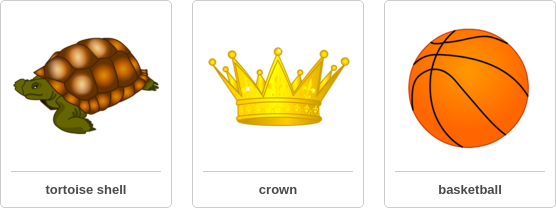
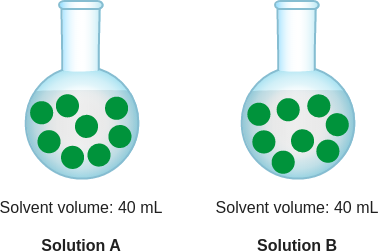
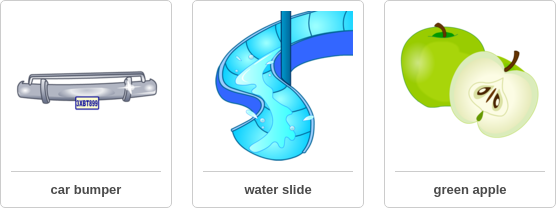
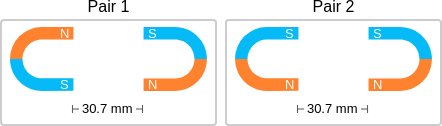
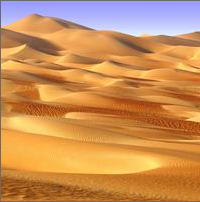
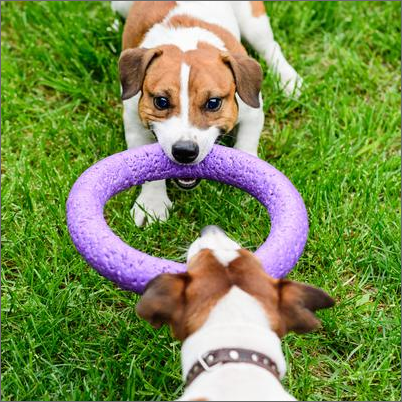
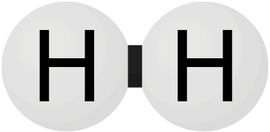
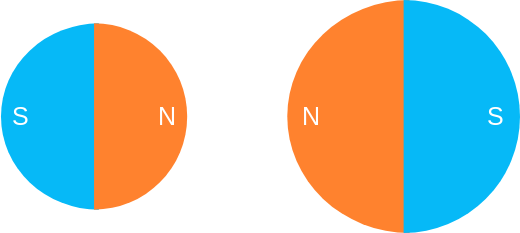
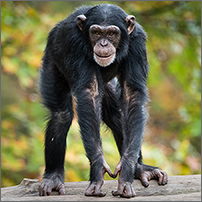
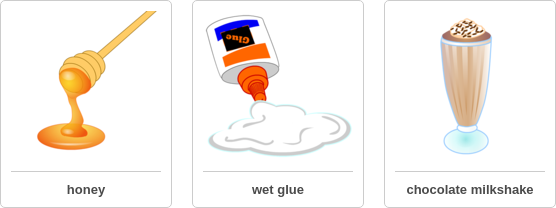
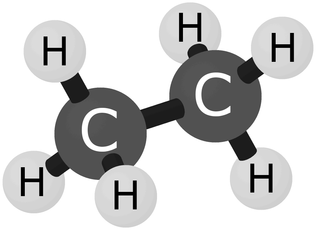
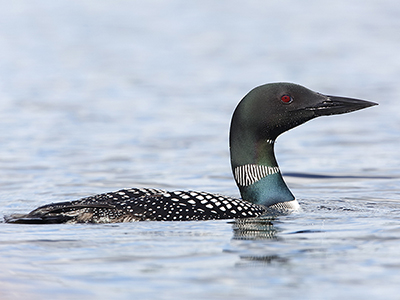
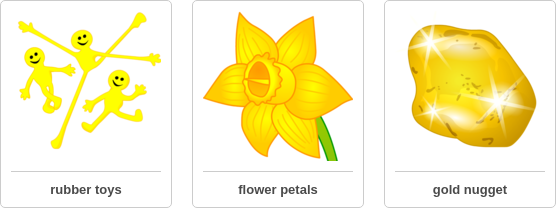
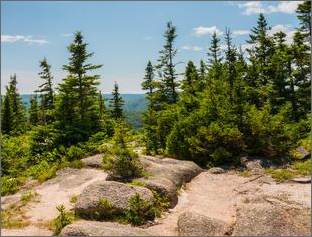
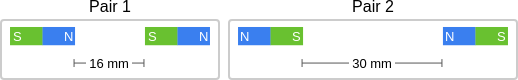
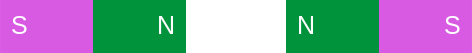
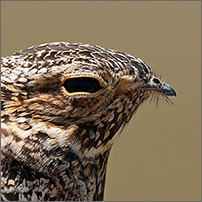
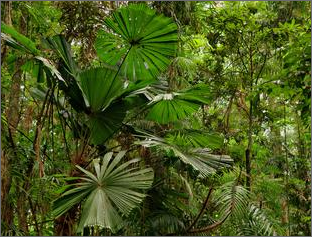
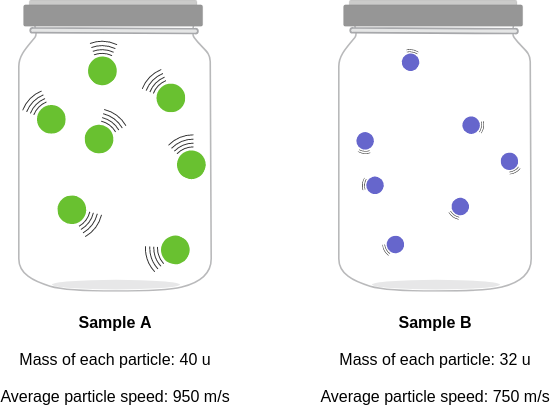
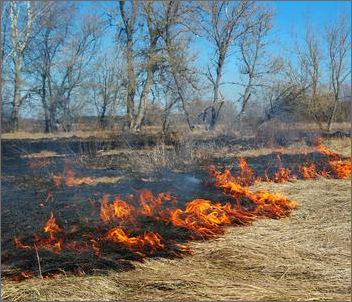
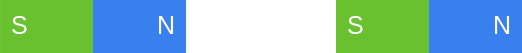
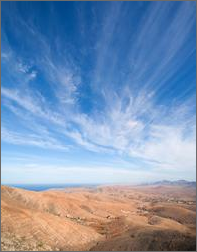
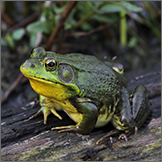
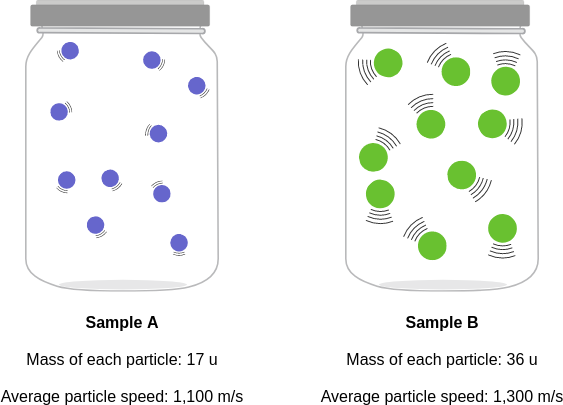
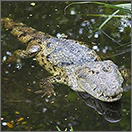
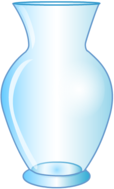
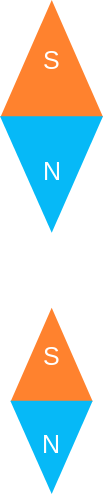
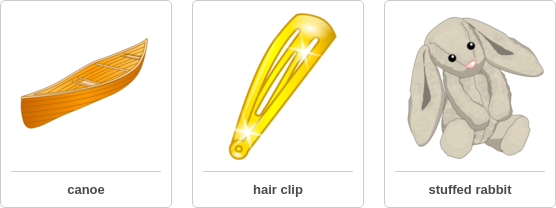
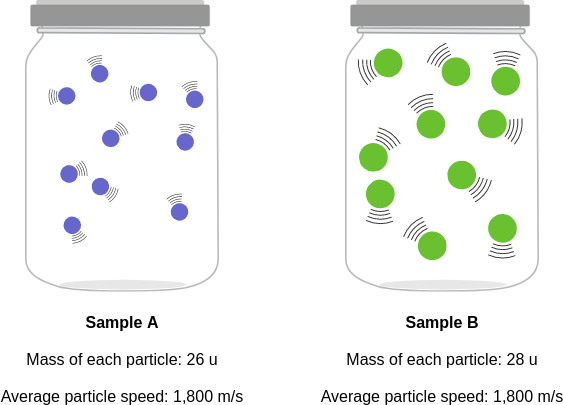
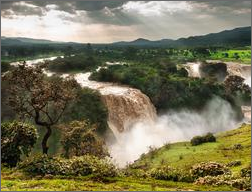
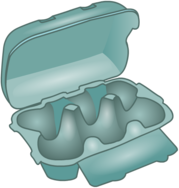
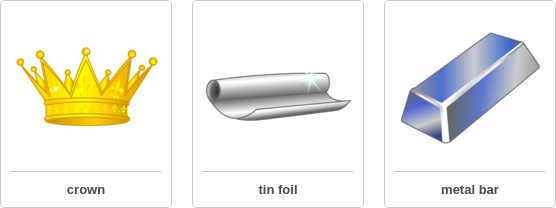
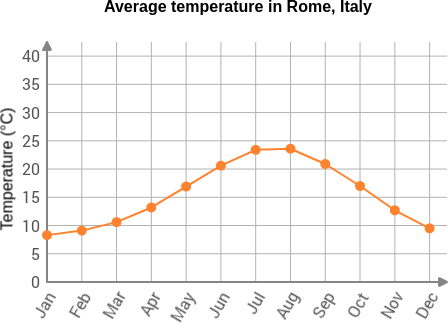
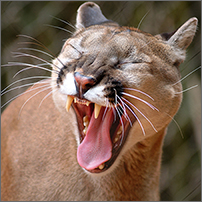
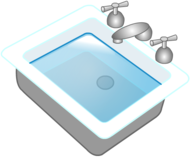
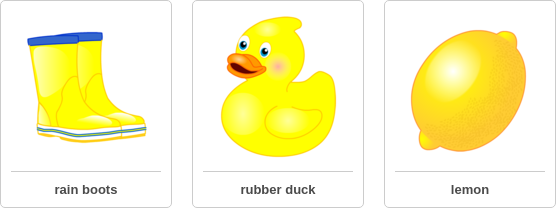
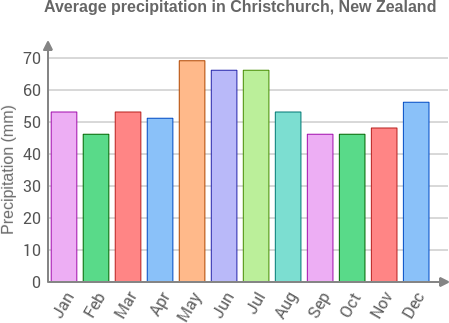
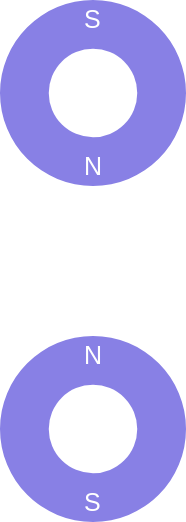
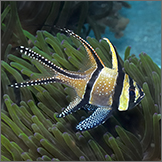
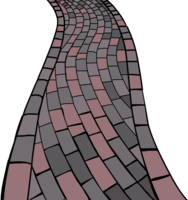
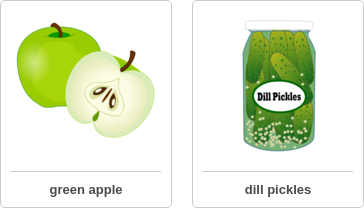
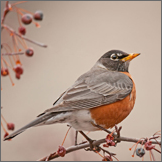
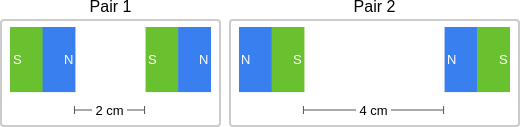
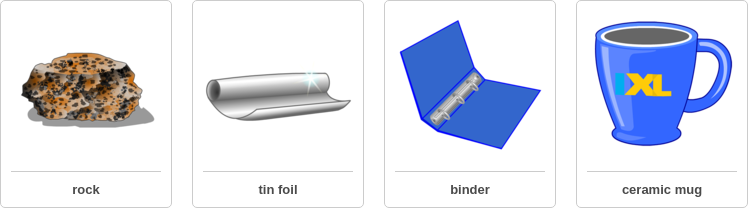
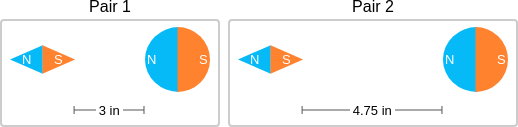
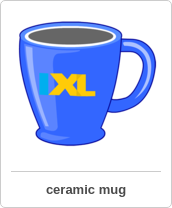
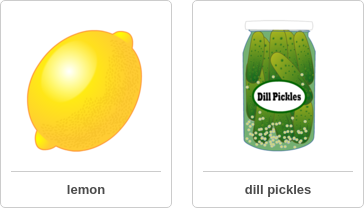
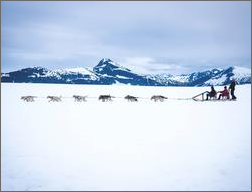
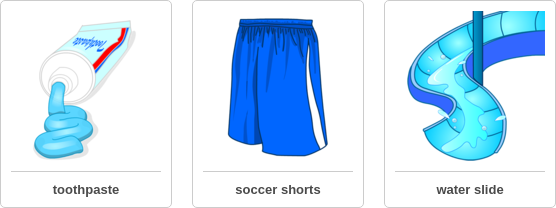
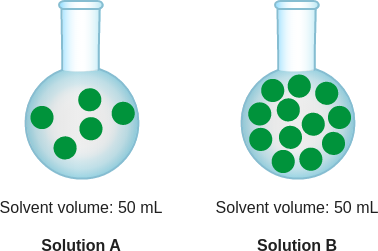
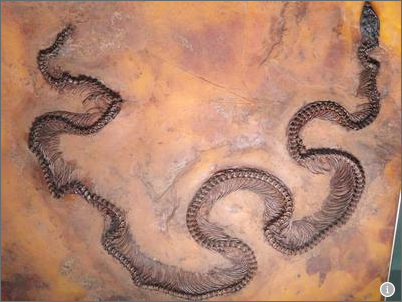
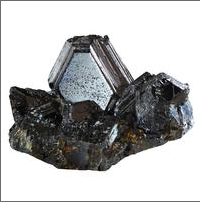
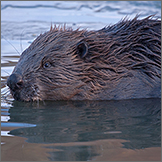
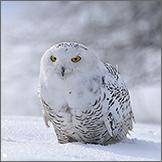
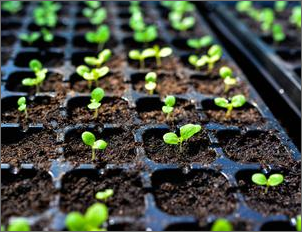
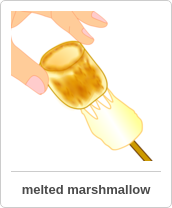
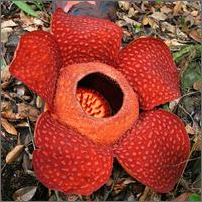
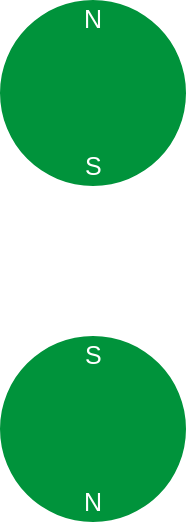
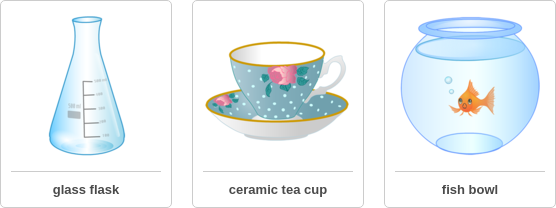
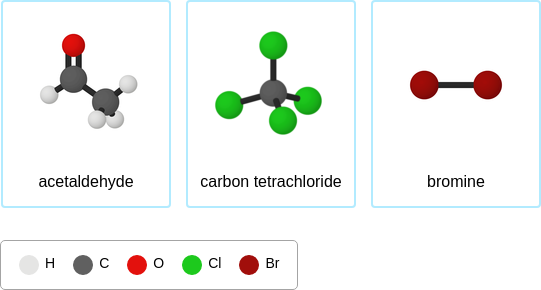
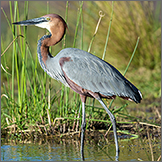
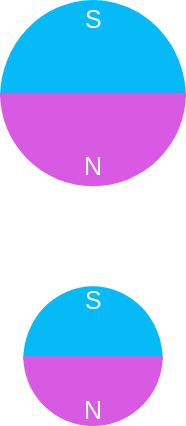
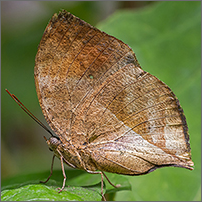
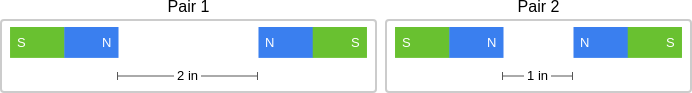

In [23]:
import html
from pathlib import Path
from IPython.display import display, HTML

ARTIFACTS = Path("artifacts").resolve()
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Только id_test — не используем ood_test и general_test
id_test_records = [r for r in records if r.get("split") == "id_test"]
id_test_records = sorted(id_test_records, key=lambda r: str(r.get("id", "")))

print(f"Найдено примеров: {len(id_test_records)}")

cards = []

for r in id_test_records:
    example_id = str(r.get("id", "NO_ID"))
    image_path = Path(str(r.get("image", "")))

    # Если относительный путь не найден, пробуем путь относительно текущей папки
    if not image_path.is_absolute():
        image_path = Path.cwd() / image_path

    question = html.escape(str(r.get("question", "")))

    if image_path.exists():
        # Встраиваем изображение в HTML как base64, чтобы галерея была автономной
        import base64
        import mimetypes

        mime = mimetypes.guess_type(image_path.name)[0] or "image/jpeg"
        encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
        img_html = (
            f'<img src="data:{mime};base64,{encoded}" '
            f'alt="ID {html.escape(example_id)}">'
        )
    else:
        img_html = (
            f'<div class="missing">Изображение не найдено<br>'
            f'{html.escape(str(image_path))}</div>'
        )

    cards.append(f"""
    <div class="card">
      <h3>ID: {html.escape(example_id)}</h3>
      {img_html}
      <p>{question}</p>
    </div>
    """)

document = f"""<!DOCTYPE html>
<html lang="ru">
<head>
<meta charset="UTF-8">
<title>ScienceQA — id_test</title>
<style>
body {{
  font-family: Arial, sans-serif;
  margin: 20px;
  background: #f5f5f5;
}}
h1 {{ margin-bottom: 8px; }}
.grid {{
  display: grid;
  grid-template-columns: repeat(4, minmax(0, 1fr));
  gap: 16px;
}}
.card {{
  background: white;
  border: 1px solid #ddd;
  border-radius: 8px;
  padding: 12px;
  overflow-wrap: anywhere;
}}
.card img {{
  width: 100%;
  height: 220px;
  object-fit: contain;
  background: #eee;
}}
.card h3 {{ margin-top: 0; }}
.missing {{
  height: 220px;
  display: flex;
  align-items: center;
  justify-content: center;
  background: #eee;
  text-align: center;
  overflow-wrap: anywhere;
}}
@media (max-width: 1000px) {{
  .grid {{ grid-template-columns: repeat(2, minmax(0, 1fr)); }}
}}
@media (max-width: 600px) {{
  .grid {{ grid-template-columns: 1fr; }}
}}
</style>
</head>
<body>
<h1>ScienceQA: id_test</h1>
<p>Всего примеров: {len(id_test_records)}. Для разметки используй ID карточек.</p>
<div class="grid">
{''.join(cards)}
</div>
</body>
</html>
"""

gallery_path = ARTIFACTS / "id_test_gallery.html"
gallery_path.write_text(document, encoding="utf-8")

print(f"HTML сохранён: {gallery_path}")
display(HTML(document))

In [ ]:

import json
import re
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

ARTIFACTS = Path("artifacts").resolve()
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Гипотеза:
# после дообучения SFT модель сильнее улучшает ответы на вопросы
# по фотографиям реальных объектов, чем на вопросы по рисункам.
#
# Проверяем её на двух группах примеров из id_test:
# 1. Фотографии
# 2. Рисунки
#
# Для каждой группы сравниваем точность Base и SFT.
# Поскольку обе группы небольшие, результаты рассматриваем как наблюдение,
# а не как окончательное доказательство гипотезы.

drawing_ids = [
    10, 104, 107, 110, 136, 148, 154, 157, 167, 17, 172,
    180, 194, 236, 243, 247, 249, 253, 257, 263, 80, 94
]

photo_ids = [
    116, 123, 150, 161, 168, 177, 18, 185, 207, 219, 241,
    256, 272, 349, 36, 382, 397, 398, 400, 402, 49, 78
]

def normalize_id(value):
    """Приводит ID к числовой части, например scienceqa-test-10 -> 10."""
    match = re.search(r"(\d+)$", str(value))
    return int(match.group(1)) if match else None

drawing_set = set(drawing_ids)
photo_set = set(photo_ids)

assert not (drawing_set & photo_set), "ID рисунков и фотографий пересекаются!"
assert len(drawing_ids) == 22 and len(photo_ids) == 22

# Находим только заданные примеры из id_test.
selected = {}
for r in records:
    if r.get("split") != "id_test":
        continue
    rid = normalize_id(r.get("id", ""))
    if rid in drawing_set or rid in photo_set:
        selected[rid] = r

missing_ids = sorted((drawing_set | photo_set) - set(selected))
if missing_ids:
    print("В records не найдены ID:", missing_ids)

import json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

ARTIFACTS = Path("artifacts").resolve()
predictions_path = ARTIFACTS / "predictions.jsonl"

# ID двух групп
drawing_ids = {
    10, 104, 107, 110, 136, 148, 154, 157, 167, 17, 172,
    180, 194, 236, 243, 247, 249, 253, 257, 263, 80, 94
}

photo_ids = {
    116, 123, 150, 161, 168, 177, 18, 185, 207, 219, 241,
    256, 272, 349, 36, 382, 397, 398, 400, 402, 49, 78
}

assert not (drawing_ids & photo_ids), "ID групп пересекаются!"

# Загружаем предсказания
with predictions_path.open("r", encoding="utf-8") as f:
    predictions = [json.loads(line) for line in f if line.strip()]

rows = []

for p in predictions:
    # Используем только id_test
    if p.get("split") != "id_test":
        continue

    # scienceqa-test-104 -> 104
    example_id = int(p["id"].rsplit("-", 1)[-1])

    if example_id in drawing_ids:
        group = "Рисунки"
    elif example_id in photo_ids:
        group = "Фотографии"
    else:
        continue

    gold = str(p["gold"]).strip().upper()
    base = str(p["base_prediction"]).strip().upper()
    sft = str(p["sft_prediction"]).strip().upper()

    rows.append({
        "id": p["id"],
        "Тип изображения": group,
        "Правильный ответ": gold,
        "Base": base,
        "SFT": sft,
        "Base верно": base == gold,
        "SFT верно": sft == gold,
    })

details = pd.DataFrame(rows)

if details.empty:
    raise ValueError(
        "Не найдено совпадений. Проверь путь к predictions.jsonl "
        "и ID примеров."
    )

# Проверяем, что все заданные ID присутствуют в id_test
found_ids = {
    int(x.rsplit("-", 1)[-1])
    for x in details["id"]
}
missing_ids = sorted((drawing_ids | photo_ids) - found_ids)

print(f"Найдено примеров: {len(details)} из 44")
if missing_ids:
    print("Не найдены в predictions.jsonl:", missing_ids)

# Сводная таблица
summary_rows = []

for group in ["Фотографии", "Рисунки"]:
    part = details[details["Тип изображения"] == group]
    n = len(part)

    if n == 0:
        continue

    base_acc = part["Base верно"].mean() * 100
    sft_acc = part["SFT верно"].mean() * 100

    summary_rows.append({
        "Тип изображения": group,
        "Примеров": n,
        "Base, %": round(base_acc, 2),
        "SFT, %": round(sft_acc, 2),
        "Изменение, п.п.": round(sft_acc - base_acc, 2),
    })

summary = pd.DataFrame(summary_rows)

display(Markdown("## Бонусное исследование: фотографии и рисунки"))
display(Markdown(
    "**Гипотеза:** после дообучения прирост точности на фотографиях "
    "будет выше, чем на рисунках."
))
display(summary)

display(Markdown("### Предсказания по отдельным примерам"))
display(details)

# Сохраняем результаты в UTF-8
details.to_csv(
    ARTIFACTS / "bonus_photo_drawing_details.csv",
    index=False,
    encoding="utf-8-sig"
)
summary.to_csv(
    ARTIFACTS / "bonus_photo_drawing_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# Автоматический предварительный вывод
gains = dict(zip(summary["Тип изображения"], summary["Изменение, п.п."]))

if "Фотографии" in gains and "Рисунки" in gains:
    photo_gain = gains["Фотографии"]
    drawing_gain = gains["Рисунки"]

    if photo_gain > drawing_gain:
        conclusion = (
            "Результаты согласуются с гипотезой: прирост на фотографиях "
            "выше, чем на рисунках."
        )
    elif photo_gain < drawing_gain:
        conclusion = (
            "Результаты не поддерживают гипотезу: прирост на рисунках "
            "выше, чем на фотографиях."
        )
    else:
        conclusion = (
            "Прирост точности одинаков для обеих групп. "
            "Гипотеза не получила явной поддержки."
        )

    display(Markdown("### Предварительный вывод"))
    display(Markdown(
        conclusion + "\n\n"
        "В каждой группе не более 22 примеров, поэтому результат "
        "следует считать предварительным, а не универсальным выводом."
    ))

print("Результаты сохранены в:", ARTIFACTS)


Найдено примеров: 44 из 44


## Бонусное исследование: фотографии и рисунки

**Гипотеза:** после дообучения прирост точности на фотографиях будет выше, чем на рисунках.

,Тип изображения,Примеров,"Base, %","SFT, %","Изменение, п.п."
0,Фотографии,22,72.73,86.36,13.64
1,Рисунки,22,81.82,81.82,0.00


### Предсказания по отдельным примерам

,id,Тип изображения,Правильный ответ,Base,SFT,Base верно,SFT верно
0,scienceqa-test-10,Рисунки,C,C,C,True,True
1,scienceqa-test-104,Рисунки,B,B,A,True,False
2,scienceqa-test-107,Рисунки,A,A,A,True,True
3,scienceqa-test-110,Рисунки,C,C,C,True,True
4,scienceqa-test-116,Фотографии,A,A,A,True,True
5,scienceqa-test-123,Фотографии,B,B,B,True,True
6,scienceqa-test-136,Рисунки,A,A,A,True,True
7,scienceqa-test-148,Рисунки,A,A,A,True,True
8,scienceqa-test-150,Фотографии,A,A,A,True,True
9,scienceqa-test-154,Рисунки,C,C,C,True,True


### Предварительный вывод

Результаты согласуются с гипотезой: прирост на фотографиях выше, чем на рисунках.

В каждой группе не более 22 примеров, поэтому результат следует считать предварительным, а не универсальным выводом.

Результаты сохранены в: /content/artifacts


## Анализ результатов

После дообучения качество модели улучшилось на всех трёх отложенных выборках: на `id_test` — с 82.81% до 87.50% (+4.69 п.п.), на `ood_test` — с 56.25% до 68.75% (+12.5 п.п.), на `general_test` — с 87.50% до 89.06% (+1.56 п.п.). Наибольший прирост получен на вопросах по естественным наукам для старших классов. Это показывает, что дообучение помогло модели, но эффект зависит от типа заданий.

В бонусном исследовании проверялась гитотеза о том, что после дообучения SFT модель сильнее улучшит ответы на вопросы по фотографиям реальных объектов, чем на вопросы по рисункам (поскольку на реальных фотографиях больше деталей). Результат эксперимента подтвердил эту гипотезу: точность на реальных фотографиях выросла на 13.64%, тогда как точность на рисунках не выросла вообще.

Исследование ограничено одним датасетом и строгой метрикой, которая не засчитывает ответы с дополнительным текстом. В целом SFT улучшил результаты на всех трёх отложенных выборках, однако это не гарантирует улучшения на любых задачах.